# 03 — Why random whistles trigger the detector, and two path vetoes that stop it

`detect-tests` (2026-11-21) holds clips recorded on the detector page: four false positives
(an unrelated tune, a random whistle, two unregistered 3-note patterns), four true patterns and two
coughs. On the live server the false positives scored ρ̂ = 152–523 while true patterns scored
173–948: **no threshold on ρ̂ separates them**. This notebook finds out why and adds three
signal-based vetoes on the Viterbi path (`search.consistency`, applied in `detect.detect`).

In [1]:
import json, pathlib, warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import wavfile
from scipy.signal import resample_poly
from whistle_lab import detect, search as gw

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.rcParams.update({"figure.dpi": 80, "font.size": 9})
DATA = pathlib.Path("../data")
TPL = detect.templates(DATA / "default")
for l, t in TPL.items():
    print(f"{l:10s} steps {np.round(t['steps'], 2)} st, durations {np.round(t['durations'], 2)} s, {t['n_examples']} examples")

def load(ds):
    out = []
    for p in sorted((DATA / ds).glob("*.json")):
        m = json.loads(p.read_text())
        sr, x = wavfile.read(p.with_suffix(".wav"))
        out.append(dict(ds=ds, label=m["label"], id=m["id"], live=m["notes"], x=x.astype(np.float32) / 32768, sr=sr))
    return out

recs = load("default") + load("detect-tests")
truth = lambda r: r["label"] if r["label"] in TPL else None
for r in recs:
    if r["ds"] == "detect-tests":
        print(f"{r['label'][:50]:50s} live: {r['live'].removeprefix('detector page: ')}")

Lights on  steps [ 9.46 -3.66] st, durations [0.27 0.56 0.45] s, 5 examples
Lights off steps [-4.4  -4.55] st, durations [0.25 0.28 0.54] s, 4 examples
Whistling a tune that is an unrelated tune         live: ✓ Lights onbest: Lights on, ρ̂ = 333 (threshold 90)
Coughing one                                       live: No signalbest: Lights on, ρ̂ = 50 (threshold 90)
Coughing two                                       live: No signalbest: Lights on, ρ̂ = 71 (threshold 90)
Another random whistle                             live: ✓ Lights offbest: Lights off, ρ̂ = 152 (threshold 90)
Lights off                                         live: ✓ Lights offbest: Lights off, ρ̂ = 948 (threshold 90)
Whistling a pattern which is not registered        live: ✓ Lights onbest: Lights on, ρ̂ = 305 (threshold 90)
Lights on                                          live: ✓ Lights onbest: Lights on, ρ̂ = 173 (threshold 90)
Lights on                                          live: ✓ Lights onbest: Lights on, ρ̂

## 1. What the false-positive tracks look like

Best path per pattern for each `detect-tests` clip, drawn on the whitened spectrogram, coloured by
note. The Viterbi state lets the cell move ±1 per frame within a note at cost 3, while a tonal pixel
earns up to ~7: **gliding along a melody is cheaper than leaving it**. So a "note" can be a
whole run of the tune, and the median-to-median steps of the false positives bear little resemblance
to the template (e.g. "another pattern" → Lights on: 2255 → 3098 → 1483 Hz is +5.5, −12.6 st against
a template of +9.5, −3.7).

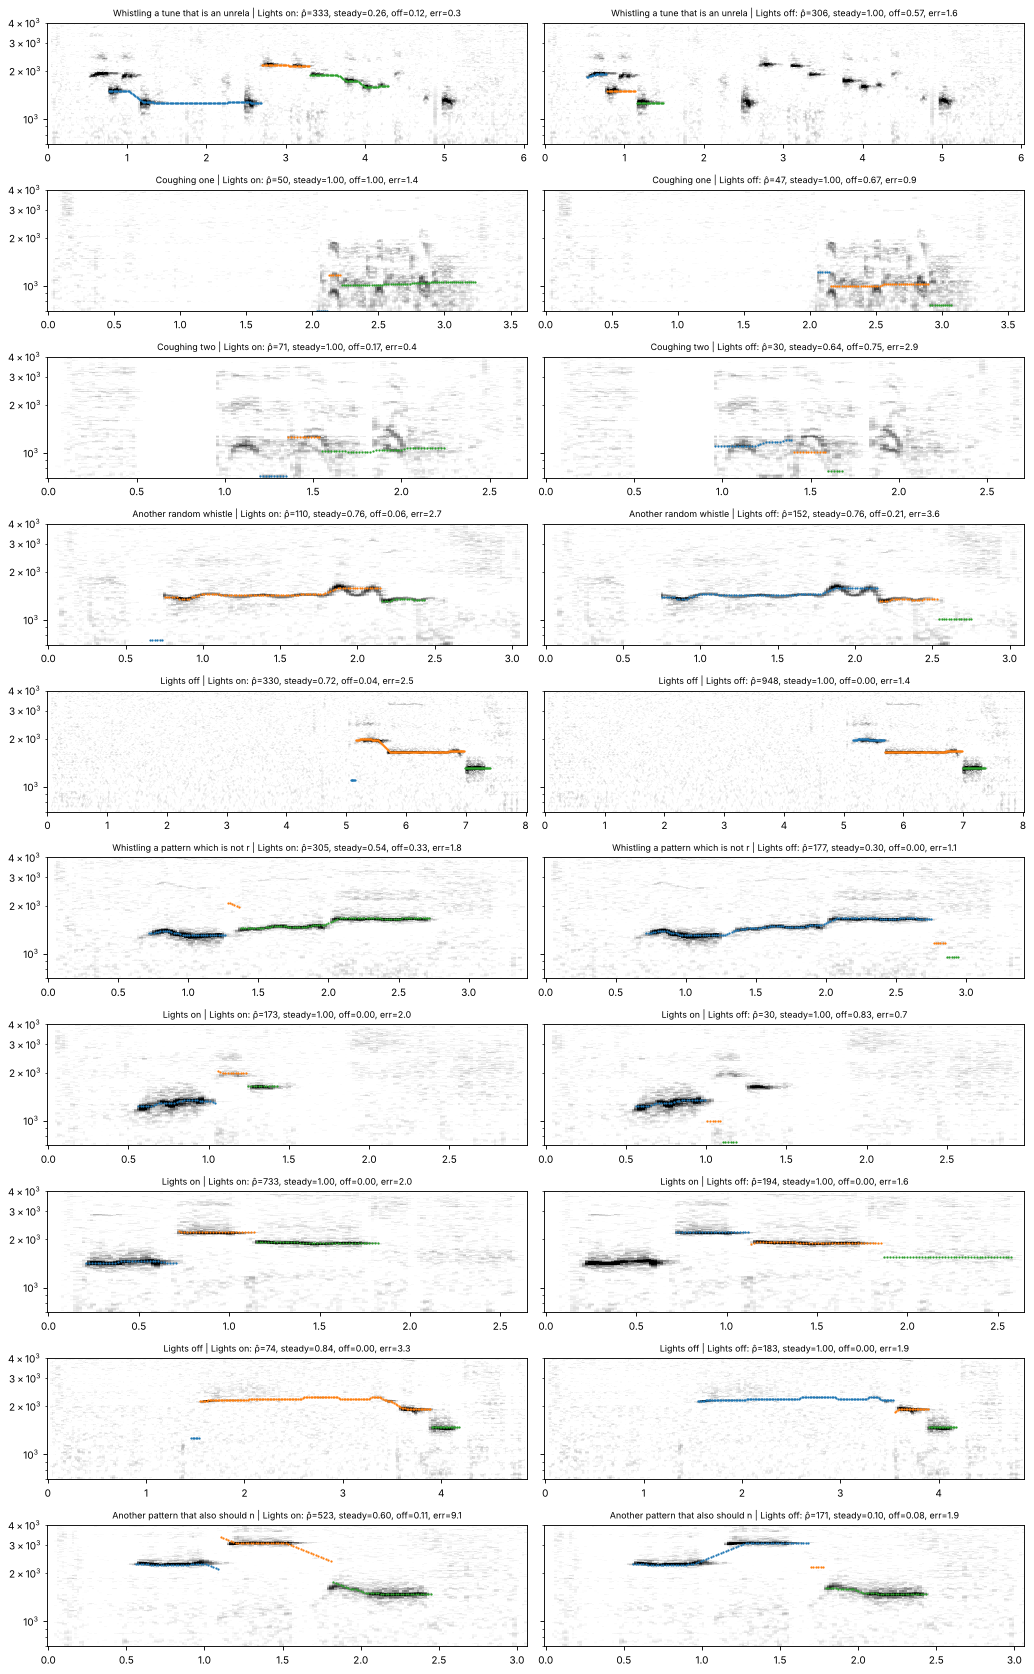

In [2]:
def best_path(x16, tp):
    s, z = gw.pixel_score(x16)
    tr = gw.viterbi(s, tp["steps"], keep_path=True)
    rw = tr.reweighted(detect.CHI0)
    b = int(np.argmax(rw))
    fr, cells, ks = tr.path(b)
    return s, z, rw[b], fr, cells, ks

tests = [r for r in recs if r["ds"] == "detect-tests"]
fig, axes = plt.subplots(len(tests), 2, figsize=(13, 2.1 * len(tests)), sharey=True)
for row, r in zip(axes, tests):
    x16 = resample_poly(r["x"].astype(np.float64), gw.FS, r["sr"])
    for ax, (l, tp) in zip(row, TPL.items()):
        s, z, rho, fr, cells, ks = best_path(x16, tp)
        t = np.arange(len(s)) * gw.DT
        ax.pcolormesh(t, gw.GRID_HZ, 10 * np.log10(z.T), shading="auto", vmin=0, vmax=40, cmap="Greys")
        for k in range(3):
            m = ks == k
            ax.plot(fr[m] * gw.DT, gw.GRID_HZ[cells[m]], ".", ms=2, color=f"C{k}")
        stdy, off, err, _ = gw.consistency(s, fr, cells, ks, tp["steps"])
        ax.set_title(f"{r['label'][:34]} | {l}: ρ̂={rho:.0f}, steady={stdy:.2f}, off={off:.2f}, err={err:.1f}", fontsize=8)
        ax.set_yscale("log"); ax.set_ylim(gw.F_LO, gw.F_HI)
fig.tight_layout()

## 2. Does a higher drift cost fix it?

The obvious fix in the HMM is to make within-note drift expensive. It doesn't separate the classes:
ρ̂ is a sum over pixels, so it scales with how long and loud the whistle is. A loud wrong pattern
keeps more score than a short, quiet right one (the 0.9 s "Lights on" drops to 87 at cost 20,
below "unrelated tune" at 255–297).

In [3]:
print(f"{'':44s}" + "".join(f"{'drift cost ' + str(d):>16s}" for d in (3, 6, 10, 20)))
for r in tests:
    s, _ = gw.pixel_score(resample_poly(r["x"].astype(np.float64), gw.FS, r["sr"]))
    cols = []
    for dc in (3, 6, 10, 20):
        v = [gw.viterbi(s, tp["steps"], drift_cost=dc).reweighted(detect.CHI0).max() for tp in TPL.values()]
        cols.append("/".join(f"{a:5.0f}" for a in v))
    print(f"{r['label'][:42]:42s}  " + "".join(f"{c:>16s}" for c in cols))
print("(columns: ρ̂ for Lights on / Lights off)")

                                                drift cost 3    drift cost 6   drift cost 10   drift cost 20


Whistling a tune that is an unrelated tune         333/  306       334/  300       281/  297       255/  297


Coughing one                                        50/   47        45/   42        74/   40        74/   41


Coughing two                                        71/   30        78/   16        78/   16        78/   16


Another random whistle                             110/  152        95/  132        83/  112        63/   24


Lights off                                         330/  948       314/  944       294/  940       273/  930


Whistling a pattern which is not registere         305/  177       264/  161       242/  144       191/  105


Lights on                                          173/   30       100/   27        94/   24        87/   19


Lights on                                          733/  194       715/  190       694/  185       660/  179


Lights off                                          74/  183        90/  151        90/  226        90/  226


Another pattern that also should not be re         523/  171       394/  146       155/  139       151/  122
(columns: ρ̂ for Lights on / Lights off)


## 3. Three path vetoes

All are computed on the best path only, so they cost nothing next to the Viterbi recursion
(and would be cheap on the ESP32 too). Each is evaluated **per note** and the worst note counts: a
first version used whole-track fractions, and the synthetic test in §5 showed a 0.1 s phantom note
(through a gap or across a legato glide) hides easily in a 2 s track.

- **Steadiness**: fraction of the note's frames within ±0.75 st of its median pitch. A whistled note
  wobbles but rarely wanders; a path that glides through a tune does. Veto below **0.75** (real true
  patterns ≥ 0.82, synthetic ones 1.00).
- **Off-path**: fraction of the note's frames where the loudest tonal pixel (s > 2, z ≳ 17 dB) is more
  than 1 st away from the path. Catches the opposite trick: a steady path sitting on one note while
  the whistler plays others (the tune's Lights-off match), phantom notes, and coughs. Veto above
  **0.3** (real true patterns ≤ 0.08, synthetic ≤ 0.22).
- **Step error**: largest |median-to-median step − template step|. The HMM's jump tolerance is ±1.5 st,
  but a path can jump in mid-glide and then drift; this checks the intervals the notes actually
  have. Veto above **2.5 st** (real true patterns ≤ 2.0, synthetic with 0.7 st jitter ≤ 1.9).

`detect.detect` now checks the top 3 ρ̂ peaks (≥ 1 s apart) for each pattern and keeps the strongest
that passes, so a vetoed impostor early in a clip cannot hide a genuine pattern later.

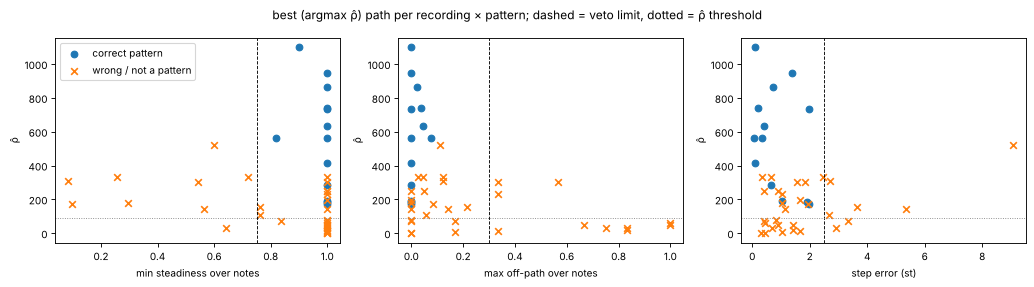

In [4]:
rows = []
for r in recs:
    x16 = resample_poly(r["x"].astype(np.float64), gw.FS, r["sr"])
    for l, tp in TPL.items():
        s, z, rho, fr, cells, ks = best_path(x16, tp)
        if not np.isfinite(rho) or rho < 0:
            continue
        stdy, off, err, _ = gw.consistency(s, fr, cells, ks, tp["steps"])
        rows.append(dict(rho=rho, steady=stdy, off=off, err=err, right=truth(r) == l))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
limits = [("steady", detect.MIN_STEADINESS, "min steadiness over notes"),
          ("off", detect.MAX_OFF_PATH, "max off-path over notes"),
          ("err", detect.MAX_STEP_ERROR_ST, "step error (st)")]
for ax, (key, lim, name) in zip(axes, limits):
    for right, mk, lab in [(True, "o", "correct pattern"), (False, "x", "wrong / not a pattern")]:
        sel = [q for q in rows if q["right"] == right]
        ax.scatter([q[key] for q in sel], [q["rho"] for q in sel], marker=mk, label=lab)
    ax.axvline(lim, color="k", lw=0.8, ls="--"); ax.axhline(detect.THRESHOLD, color="grey", lw=0.8, ls=":")
    ax.set_xlabel(name); ax.set_ylabel("ρ̂")
axes[0].legend()
fig.suptitle("best (argmax ρ̂) path per recording × pattern; dashed = veto limit, dotted = ρ̂ threshold")
fig.tight_layout()

## 4. Before and after, all 25 recordings

"before" is the live detector (argmax ρ̂ ≥ 90); "after" is `detect.detect` with the vetoes.
Note the templates come from `default`, so the `default` rows are in-sample; `detect-tests` is not.

In [5]:
def run(r, vetoes=True):
    saved = detect.MIN_STEADINESS, detect.MAX_OFF_PATH, detect.MAX_STEP_ERROR_ST
    if not vetoes:
        detect.MIN_STEADINESS, detect.MAX_OFF_PATH, detect.MAX_STEP_ERROR_ST = 0.0, np.inf, np.inf
    try:
        return detect.detect(r["x"], r["sr"], TPL)
    finally:
        detect.MIN_STEADINESS, detect.MAX_OFF_PATH, detect.MAX_STEP_ERROR_ST = saved

print(f"{'recording':44s}{'truth':>11s}{'before':>13s}{'after':>13s}   best unvetoed ρ̂")
n_ok = [0, 0]
for r in recs:
    b, a = run(r, False), run(r)
    ok = [res["label"] == truth(r) for res in (b, a)]
    n_ok = [n + o for n, o in zip(n_ok, ok)]
    rho = next((c["rho"] for c in a["candidates"] if c["veto"] is None and c["rho"] is not None), None)
    mark = lambda res, o: f"{str(res['label'])[7:] if res['label'] else '—'}{'' if o else ' ✗'}"
    print(f"{r['ds'][:3]} {r['label'][:40]:40s}{str(truth(r))[7:] if truth(r) else '—':>11s}"
          f"{mark(b, ok[0]):>13s}{mark(a, ok[1]):>13s}   {rho if rho is None else round(rho)}")
print(f"\ncorrect: before {n_ok[0]}/{len(recs)}, after {n_ok[1]}/{len(recs)}")

recording                                         truth       before        after   best unvetoed ρ̂
def Lights on                                        on           on           on   566


def Lights on                                        on           on           on   193
def Lights on                                        on           on           on   634


def Lights on                                        on           on           on   738


def Lights on                                        on           on           on   863


def Background noise                                  —            —            —   -7


def Background noise                                  —            —            —   -4


... (10 outputs left out)

det Lights off                                      off          off          off   948


det Whistling a pattern which is not registe          —         on ✗            —   -23
det Lights on                                        on           on           on   173


det Lights on                                        on           on           on   733


det Lights off                                      off          off          off   183
det Another pattern that also should not be           —         on ✗            —   -26

correct: before 21/25, after 25/25


The "best unvetoed ρ̂" column shows how much room the threshold of 90 has on each side.

## 5. Synthetic check: are the vetoes fitted to four recordings?

Four false positives are too few to trust thresholds against, so inject synthetic whistles into the
real background and speech recordings:

- **true patterns**: the template's steps with per-step error N(0, 0.7 st), each note's duration
  0.6–1.6 × the template's, a slow pitch drift within each note of up to ±0.5 st, 5 Hz vibrato of
  ±15 cents, 40 ms glides between notes and occasional short gaps;
- **wrong 3-note patterns**: the same, with both steps drawn uniformly from ±12 st; only those more
  than 3 st from both templates on some step count as "wrong";
- **tunes**: 5–8 notes, integer steps of ±1–5 st, 0.15–0.4 s each, like an unrelated melody. Tunes
  that happen to contain both template steps consecutively (within 1.5 st) are counted separately.

All notes are kept within 800–3500 Hz. Band SNR (700–4000 Hz) is swept for the true patterns, so we can see whether noisy paths start
failing the steadiness test.

In [6]:
rng = np.random.default_rng(3)
FS = 16_000
noise_pool = [resample_poly(r["x"].astype(np.float64), FS, r["sr"]) for r in recs
              if r["label"] in ("Background noise", "Talking")]

def band_power(x):
    X = np.fft.rfft(x); f = np.fft.rfftfreq(len(x), 1 / FS)
    return np.sum(np.abs(X[(f > gw.F_LO) & (f < gw.F_HI)]) ** 2) / len(x) ** 2

def synth(semis, durs, f0):
    # semis: note pitches in semitones relative to f0
    f, amp = [], []
    for k, (p, d) in enumerate(zip(semis, durs)):
        n = int(d * FS)
        drift = np.linspace(0, rng.uniform(-0.5, 0.5), n)
        tone = f0 * 2 ** ((p + drift) / 12) * 2 ** (15 / 1200 * np.sin(2 * np.pi * 5 * np.arange(n) / FS))
        g = int(0.04 * FS)
        if k and rng.random() > 0.3:                       # legato: glide from the previous note
            tone[:g] = np.linspace(f[-1][-1], tone[g], g)
            a = np.ones(n)
        else:                                               # tongued: short gap
            a = np.clip(np.minimum(np.arange(n), n - np.arange(n)) / (0.01 * FS), 0, 1)
            a[: int(rng.uniform(0, 0.08) * FS)] = 0
        f.append(tone); amp.append(a)
    f, amp = np.concatenate(f), np.concatenate(amp)
    ph = 2 * np.pi * np.cumsum(f) / FS
    return amp * (np.sin(ph) + 0.05 * np.sin(2 * ph))

def embed(sig, snr_db):
    pad = int(1.0 * FS)
    bed = noise_pool[rng.integers(len(noise_pool))]
    n = len(sig) + 2 * pad
    bed = np.resize(np.roll(bed, rng.integers(len(bed))), n)
    out = bed.copy()
    out[pad:pad + len(sig)] += sig * np.sqrt(band_power(bed) * 10 ** (snr_db / 10) / band_power(sig))
    return out.astype(np.float32)

LO, HI = 800, 3500   # comfortable whistling range, inside the 700–4000 Hz search band

def f0_in_band(semis):
    span = np.max(semis) - np.min(semis)
    if span > 12 * np.log2(HI / LO):
        return None
    lo = LO * 2 ** (-np.min(semis) / 12)
    return np.exp(rng.uniform(np.log(lo), np.log(lo * HI / LO / 2 ** (span / 12))))

def true_pattern(label):
    tp = TPL[label]
    semis = np.r_[0, np.cumsum(tp["steps"] + rng.normal(0, 0.7, len(tp["steps"])))]
    return synth(semis, tp["durations"] * rng.uniform(0.6, 1.6, len(tp["durations"])), f0_in_band(semis))

def wrong_pattern():
    while (f0 := f0_in_band(semis := np.r_[0, np.cumsum(steps := rng.uniform(-12, 12, 2))])) is None:
        pass
    clearly_wrong = all(np.abs(steps - tp["steps"]).max() > 3 for tp in TPL.values())
    return synth(semis, rng.uniform(0.2, 0.7, 3), f0), clearly_wrong

def tune():
    n = rng.integers(5, 9)
    while True:
        steps = rng.integers(1, 6, n - 1) * rng.choice([-1, 1], n - 1)
        if (f0 := f0_in_band(semis := np.r_[0, np.cumsum(steps)])) is not None:
            break
    hit = any(np.abs(steps[i:i + 2] - tp["steps"]).max() <= 1.5 for tp in TPL.values() for i in range(n - 2))
    return synth(semis, rng.uniform(0.15, 0.4, n), f0), hit

def verdicts(x):
    clip = dict(x=x, sr=FS)
    return run(clip, False)["label"], run(clip)["label"]

SNR  -6 dB: before 0.58  after 0.55
SNR  +0 dB: before 0.98  after 0.97
SNR  +6 dB: before 1.00  after 1.00
SNR +12 dB: before 1.00  after 1.00
SNR +20 dB: before 1.00  after 0.98


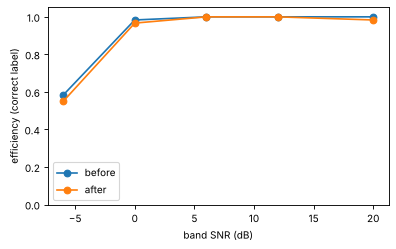

In [7]:
SNRS = [-6, 0, 6, 12, 20]
N_TRUE = 30
eff = {k: np.zeros(len(SNRS)) for k in ("before", "after")}
for i, snr in enumerate(SNRS):
    for label in TPL:
        for _ in range(N_TRUE):
            b, a = verdicts(embed(true_pattern(label), snr))
            eff["before"][i] += b == label
            eff["after"][i] += a == label
n_per = N_TRUE * len(TPL)
fig, ax = plt.subplots(figsize=(5.5, 3.2))
for k, v in eff.items():
    ax.plot(SNRS, v / n_per, "o-", label=k)
ax.set_xlabel("band SNR (dB)"); ax.set_ylabel("efficiency (correct label)"); ax.set_ylim(0, 1.05); ax.legend()
for snr, b, a in zip(SNRS, eff["before"], eff["after"]):
    print(f"SNR {snr:+3d} dB: before {b / n_per:.2f}  after {a / n_per:.2f}")

In [8]:
N_NEG, SNR = 150, 12
counts = {}
for kind, gen in [("wrong 3-note", wrong_pattern), ("tune", tune)]:
    for _ in range(N_NEG):
        sig, flag = gen()
        b, a = verdicts(embed(sig, SNR))
        key = (kind, flag)
        c = counts.setdefault(key, np.zeros(3))
        c += [1, b is not None, a is not None]
names = {("wrong 3-note", True): "wrong 3-note (>3 st off on a step)",
         ("wrong 3-note", False): "3-note within 3 st of a template",
         ("tune", False): "tune, no embedded pattern",
         ("tune", True): "tune containing the pattern's steps"}
print(f"{'':40s}{'n':>5s}{'triggered before':>18s}{'after':>8s}   (SNR {SNR} dB)")
for key, (n, b, a) in sorted(counts.items(), key=lambda kv: list(names).index(kv[0])):
    print(f"{names[key]:40s}{n:5.0f}{b / n:18.2f}{a / n:8.2f}")

                                            n  triggered before   after   (SNR 12 dB)
wrong 3-note (>3 st off on a step)        128              0.89    0.12
3-note within 3 st of a template           22              1.00    0.82
tune, no embedded pattern                 118              0.94    0.14
tune containing the pattern's steps        32              1.00    0.34


## 6. Conclusions

- **Cause**: the Viterbi path's free within-note drift. A tonal pixel earns more than a cell of drift
  costs, so a "note" can follow a whole run of a melody, and a path can jump in partway through a
  legato glide. ρ̂ scales with whistle length × loudness, so a long clean wrong whistle outscores a
  short quiet right one. No ρ̂ threshold or drift cost separates them (§2), and χ² doesn't help either,
  because a gliding path spreads its score evenly across notes.
- **Fix**: three per-note vetoes on the path: steadiness ≥ 0.75, off-path ≤ 0.3, step error ≤ 2.5 st.
  `detect.detect` tries the top 3 ρ̂ peaks per pattern and keeps the best one that passes.
- **Real data**: 25/25 correct (was 21/25), so all four live false positives are now rejected. The
  highest unvetoed non-pattern is a cough at ρ̂ 71. The weakest true pattern is 173.
- **Synthetic (12 dB)**: wrong 3-note patterns that trigger fall 0.89 → 0.12 and random tunes 0.94 → 0.14.
  Efficiency on jittered true patterns is unchanged within noise at every SNR (≈0.98–1.00 from 0 dB,
  ≈0.55 at −6 dB). 3-note patterns within 3 st of a template, and tunes that contain the template's
  steps, still trigger often. That is expected: with ±0.7 st whistling error they *are* the pattern.
- **Limits**: thresholds were set against 9 real and ~100 synthetic true patterns, with margin. The
  synthetic whistles are idealised (no breathiness, constant level, one noise bed at a time).
  ρ̂ threshold 90 is unchanged, and the nearest real non-pattern is a cough at 71.
- **Next levers**, in order:
  1. **Isolation**: no tonal activity in the ~0.4 s either side. This treats a pattern as a command,
     not a phrase, and would kill most of the remaining tune triggers.
  2. **Note-duration ratios** against the template, as a soft χ²-like term.
  3. **More data**: more true patterns recorded on the detector page (sloppy and quick ones, to firm up
     the steadiness and step-error margins), and long stretches of real room audio for the FAR.